In [173]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.getOrCreate()

In [174]:
from typing import Any, List, Optional, Tuple
from pyspark.sql import DataFrame, Window
from pyspark.sql import functions as F

## Exemplo 1

In [175]:
# data = [
#     (5, 5, 181344,   7515290),
#     (5, 4, 161337,   5423364),
#     (5, 3, 319548,   3700403),
#     (5, 1, 1461203,  6720114),
#     (5, 0, 0,              0),

#     (4, 5, 64711,    4495745),
#     (4, 4, 1188065,  9066067),
#     (4, 3, 1677696, 14722180),
#     (4, 2, 6401425, 27605785),
#     (4, 1,10763213, 44461895),
#     (4, 0,       0,     9052),

#     (3, 5, 40517,    2458981),
#     (3, 4, 788068,   8181737),
#     (3, 3,2101245,  16275768),
#     (3, 2,9536756,  34032015),
#     (3, 1,18874024, 64400631),
#     (3, 0,       0,      968),

#     (2, 5, 63994,    2082020),
#     (2, 4, 607937,   7706722),
#     (2, 3,2093645,  14271236),
#     (2, 2,6326701,  28961055),
#     (2, 1,18274197, 60398807),
#     (2, 0,       0,     1588),

#     (1, 5, 56959,    2215100),
#     (1, 4, 952746,   7931608),
#     (1, 3,2059018,  17703350),
#     (1, 2,3952309,  39509761),
#     (1, 1,13391808, 87938607),
#     (1, 0,       0,        0),

#     (0, 5,      0,    308718),
#     (0, 4,      0,    857035),
#     (0, 3, 429189,  2867964),
#     (0, 2,1018541,  4458697),
#     (0, 1,6408843, 11914368),
#     (0, 0,      0,        0),
# ]

# df = spark.createDataFrame(
#     data,
#     ["band_1", "band_2", "saldo_over", "producao"]
# )

# df = (df
#       .withColumn('bad_rate', F.when(F.col('producao') != 0, 100 * F.col('saldo_over') / F.col('producao')).otherwise(0))
# )

# df.show(36, truncate=False)

## Exemplo 2

In [176]:
data = [
    # band_1, band_2, saldo_over, producao

    (5, 5,   89499,    4294202),
    (5, 4,  303467,    2386214),
    (5, 3,  202047,    2398697),
    (5, 2,  319228,    3452763),
    (5, 1,  550056,    5444433),
    (5, 0,       0,          0),

    (4, 5,   16359,    2616663),
    (4, 4,  600757,    6658138),
    (4, 3, 1910786,   10826800),
    (4, 2, 14423925,  30589525),
    (4, 1, 14065447,  47589340),
    (4, 0,       0,          0),

    (3, 5,  150283,    2175016),
    (3, 4,  660252,    6720131),
    (3, 3, 2082400,   13621758),
    (3, 2, 9423415,   42904775),
    (3, 1, 32507333, 110493160),
    (3, 0,       0,       1108),

    (2, 5,  183013,    1594221),
    (2, 4,  925807,    5340201),
    (2, 3, 3154057,   16035062),
    (2, 2, 9367082,   35145872),
    (2, 1, 34137862, 111317604),
    (2, 0,       0,          0),

    (1, 5,   34473,    2087308),
    (1, 4,  676144,    8958480),
    (1, 3, 3451601,   25259222),
    (1, 2, 19292454,  57185128),
    (1, 1, 32207965, 215398041),
    (1, 0,       0,          0),

    (0, 5,  156538,     293599),
    (0, 4, 1222356,    1860859),
    (0, 3, 2767121,    4096166),
    (0, 2, 1366027,    5026904),
    (0, 1, 4749291,   16927079),
    (0, 0,       0,       2833),
]

df = spark.createDataFrame(
    data,
    ["band_1", "band_2", "saldo_over", "producao"]
)

df = (df
      .withColumn('bad_rate', F.when(F.col('producao') != 0, 100 * F.col('saldo_over') / F.col('producao')).otherwise(0))
)

# df.show()

In [177]:
import numpy as np
import pandas as pd
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import lil_matrix


def assign_monotone_nr(
    source_df,
    approach="group_weighted",
    cutoffs=(1, 2, 5, 8, 10, 12, 15, 18, 20),
    overflow_nr=100,
    time_limit=60,
    slack_tolerance=1e-6,
):
    """
    Assign monotone NR labels using one of two bad-rate criteria:

      - "group_weighted" checks one weighted bad rate per NR_cutoff:
        total saldo_over divided by total producao for all cells assigned to
        that cutoff. The group's weighted rate must fall within its cutoff
        interval.

      - "ordered_prefix" orders cells within each NR_cutoff by individual
        bad_rate and checks the cumulative weighted rate after each cell is
        added. If some prefix rates cannot meet their cutoff intervals while
        preserving monotone labels, a two-stage solve first minimizes total
        cutoff violation, then minimizes cell-fit cost.

    In short, "group_weighted" evaluates the whole group, while
    "ordered_prefix" evaluates the group's cumulative rate as cells are added
    in order. In both approaches, NR labels cannot decrease when either
    band_1 or band_2 decreases.

    Returns the same Spark DataFrame schema for both approaches.
    """
    if approach not in {"group_weighted", "ordered_prefix"}:
        raise ValueError("approach must be 'group_weighted' or 'ordered_prefix'")

    cutoffs = sorted(int(c) for c in cutoffs)
    if not cutoffs or len(set(cutoffs)) != len(cutoffs):
        raise ValueError("cutoffs must be a nonempty sequence of unique values")
    if slack_tolerance < 0:
        raise ValueError("slack_tolerance must be nonnegative")
    if overflow_nr <= cutoffs[-1]:
        raise ValueError("overflow_nr must be greater than the largest cutoff")

    nr_labels = cutoffs + [int(overflow_nr)]
    n_labels = len(nr_labels)
    lower_cutoffs = [0.0] + [float(c) for c in cutoffs]

    cells_pdf = (
        source_df
        .select("band_1", "band_2", "saldo_over", "producao", "bad_rate")
        .toPandas()
        .sort_values(["band_1", "band_2"], ascending=[False, False])
        .reset_index(drop=True)
    )
    if cells_pdf.empty:
        raise ValueError("source_df has no cells to assign")

    n_cells = len(cells_pdf)
    n_assignment_vars = n_cells * n_labels
    cell_index = {
        (int(row.band_1), int(row.band_2)): i
        for i, row in cells_pdf.iterrows()
    }
    band1_order = sorted(cells_pdf["band_1"].unique(), reverse=True)
    band2_order = sorted(cells_pdf["band_2"].unique(), reverse=True)

    bad = cells_pdf["saldo_over"].to_numpy(dtype=float)
    exposure = cells_pdf["producao"].to_numpy(dtype=float)
    total_exposure = max(float(exposure.sum()), 1.0)

    order_acc = (
        cells_pdf.sort_values(
            ["bad_rate", "band_1", "band_2"],
            ascending=[True, False, False],
        ).index.tolist()
    )

    # Accumulation mode uses nonnegative slack variables so the solver can return
    # the closest monotone solution when strict prefix cutoffs conflict.
    slack_count = 2 * n_labels * n_cells if approach == "ordered_prefix" else 0
    n_variables = n_assignment_vars + slack_count

    rows, lower_bounds, upper_bounds = [], [], []

    def add_constraint(coefficients, lb=-np.inf, ub=np.inf):
        rows.append(coefficients)
        lower_bounds.append(lb)
        upper_bounds.append(ub)

    # Exactly one NR label per cell.
    for i in range(n_cells):
        add_constraint(
            {i * n_labels + k: 1.0 for k in range(n_labels)},
            lb=1.0,
            ub=1.0,
        )

    # Moving to a lower band value cannot lower the ordinal NR label.
    for (band1, band2), i in cell_index.items():
        pos1 = band1_order.index(band1)
        pos2 = band2_order.index(band2)
        neighbors = []
        if pos1 + 1 < len(band1_order):
            neighbors.append((band1_order[pos1 + 1], band2))
        if pos2 + 1 < len(band2_order):
            neighbors.append((band1, band2_order[pos2 + 1]))

        for neighbor in neighbors:
            if neighbor in cell_index:
                j = cell_index[neighbor]
                coefficients = {
                    i * n_labels + k: float(-k)
                    for k in range(n_labels)
                }
                coefficients.update({
                    j * n_labels + k: float(k)
                    for k in range(n_labels)
                })
                add_constraint(coefficients, lb=0.0)

    def rate_constraint_coefficients(cell_ids, label_index, cutoff):
        cutoff_fraction = cutoff / 100.0
        return {
            i * n_labels + label_index:
                float(bad[i] - cutoff_fraction * exposure[i]) / total_exposure
            for i in cell_ids
        }

    if approach == "group_weighted":
        # Each assigned NR group's aggregate weighted rate is in its interval.
        all_cells = range(n_cells)
        for k, label in enumerate(nr_labels):
            add_constraint(
                rate_constraint_coefficients(
                    all_cells, k, lower_cutoffs[k]
                ),
                lb=0.0,
            )
            if k < len(cutoffs):
                add_constraint(
                    rate_constraint_coefficients(all_cells, k, cutoffs[k]),
                    ub=0.0,
                )
    else:
        # Every prefix, restricted to cells assigned to this NR and ordered by
        # bad_rate, must stay within the cutoff interval when possible.
        for k, label in enumerate(nr_labels):
            for prefix_end in range(n_cells):
                prefix_cells = order_acc[:prefix_end + 1]

                lower_coefficients = rate_constraint_coefficients(
                    prefix_cells, k, lower_cutoffs[k]
                )
                lower_slack = (
                    n_assignment_vars + k * n_cells + prefix_end
                )
                lower_coefficients[lower_slack] = 1.0
                add_constraint(lower_coefficients, lb=0.0)

                if k < len(cutoffs):
                    upper_coefficients = rate_constraint_coefficients(
                        prefix_cells, k, cutoffs[k]
                    )
                    upper_slack = (
                        n_assignment_vars
                        + n_labels * n_cells
                        + k * n_cells
                        + prefix_end
                    )
                    upper_coefficients[upper_slack] = -1.0
                    add_constraint(upper_coefficients, ub=0.0)

    # Minimize exposure-weighted distance to bucket midpoints.
    centers = [
        (lower_cutoffs[k] + cutoff) / 2.0
        for k, cutoff in enumerate(cutoffs)
    ]
    centers.append(float(cutoffs[-1]))  # overflow bucket

    objective = np.zeros(n_variables, dtype=float)
    for i in range(n_cells):
        if exposure[i] > 0:
            rate_fraction = bad[i] / exposure[i]
            for k, center in enumerate(centers):
                objective[i * n_labels + k] = (
                    exposure[i] / total_exposure
                    * (rate_fraction - center / 100.0) ** 2
                )
        else:
            # No observed risk: choose the lowest label compatible with neighbors.
            for k in range(n_labels):
                objective[i * n_labels + k] = k * 1e-6

    constraint_matrix = lil_matrix((len(rows), n_variables), dtype=float)
    for row_idx, coefficients in enumerate(rows):
        for col_idx, value in coefficients.items():
            constraint_matrix[row_idx, col_idx] = value

    integrality = np.concatenate([
        np.ones(n_assignment_vars, dtype=int),
        np.zeros(slack_count, dtype=int),
    ])
    variable_lbs = np.zeros(n_variables)
    variable_ubs = np.concatenate([
        np.ones(n_assignment_vars),
        np.full(slack_count, np.inf),
    ])
    base_constraints = LinearConstraint(
        constraint_matrix.tocsr(),
        np.asarray(lower_bounds),
        np.asarray(upper_bounds),
    )
    solver_options = {"time_limit": time_limit}

    if slack_count:
        # Stage 1: find the smallest possible total cutoff violation.
        slack_objective = np.zeros(n_variables, dtype=float)
        slack_objective[n_assignment_vars:] = 1.0
        slack_solution = milp(
            c=slack_objective,
            integrality=integrality,
            bounds=Bounds(variable_lbs, variable_ubs),
            constraints=base_constraints,
            options=solver_options,
        )
        if not slack_solution.success:
            raise RuntimeError(
                f"{approach} slack minimization failed: "
                f"{slack_solution.message}"
            )

        minimum_slack = float(
            slack_solution.x[n_assignment_vars:].sum()
        )
        # Allow a small cushion for solver tolerances in the stage-two budget.

        # Stage 2: preserve the minimum slack, then minimize cell-fit cost.
        slack_budget = lil_matrix((1, n_variables), dtype=float)
        for slack_idx in range(n_assignment_vars, n_variables):
            slack_budget[0, slack_idx] = 1.0
        fit_solution = milp(
            c=objective,
            integrality=integrality,
            bounds=Bounds(variable_lbs, variable_ubs),
            constraints=[
                base_constraints,
                LinearConstraint(
                    slack_budget.tocsr(),
                    -np.inf,
                    minimum_slack + slack_tolerance,
                ),
            ],
            options=solver_options,
        )
        if not fit_solution.success:
            raise RuntimeError(
                f"{approach} fit minimization failed: "
                f"{fit_solution.message}"
            )
        solution = fit_solution
    else:
        # Aggregate-rate approach has hard group cutoff constraints and no slack.
        solution = milp(
            c=objective,
            integrality=integrality,
            bounds=Bounds(variable_lbs, variable_ubs),
            constraints=base_constraints,
            options=solver_options,
        )
        if not solution.success:
            raise RuntimeError(
                f"{approach} assignment failed: {solution.message}"
            )

    chosen = np.argmax(
        solution.x[:n_assignment_vars].reshape(n_cells, n_labels),
        axis=1,
    )
    cells_pdf["NR_cutoff"] = [nr_labels[k] for k in chosen]
    cells_pdf["NR_index"] = [int(k + 1) for k in chosen]

    assignments = spark.createDataFrame(
        cells_pdf[["band_1", "band_2", "NR_cutoff", "NR_index"]]
    )
    result = source_df.join(
        assignments,
        ["band_1", "band_2"],
        "left",
    )

    nr_stats = (
        result.groupBy("NR_cutoff")
        .agg(
            F.sum("saldo_over").alias("_nr_saldo_over"),
            F.sum("producao").alias("_nr_producao"),
        )
        .withColumn(
            "nr_bad_rate",
            F.when(
                F.col("_nr_producao") > 0,
                100.0 * F.col("_nr_saldo_over") / F.col("_nr_producao"),
            ),
        )
        .withColumn(
            "nr_saldo_dist",
            F.when(
                F.sum("_nr_saldo_over").over(Window.partitionBy()) != 0,
                100.0 * F.col("_nr_saldo_over") / F.sum("_nr_saldo_over").over(Window.partitionBy()),
            ),
        )
        .withColumn(
            "nr_producao_dist",
            F.when(
                F.sum("_nr_producao").over(Window.partitionBy()) != 0,
                100.0 * F.col("_nr_producao") / F.sum("_nr_producao").over(Window.partitionBy()),
            ),
        )
        .select(
            "NR_cutoff",
            F.col("_nr_producao").alias("nr_producao"),
            F.col("_nr_saldo_over").alias("nr_saldo"),
            "nr_bad_rate",
            "nr_saldo_dist",
            "nr_producao_dist",
        )
    )
    result = result.join(nr_stats, "NR_cutoff", "left")

    window_acc = (
        Window.partitionBy("NR_cutoff")
        .orderBy(
            F.col("bad_rate").asc(),
            F.col("band_1").desc(),
            F.col("band_2").desc(),
        )
        .rowsBetween(Window.unboundedPreceding, Window.currentRow)
    )
    total_window = Window.partitionBy()
    result = (
        result
        .withColumn(
            "saldo_dist",
            F.when(
                F.sum("saldo_over").over(total_window) != 0,
                100.0 * F.col("saldo_over") / F.sum("saldo_over").over(total_window),
            ),
        )
        .withColumn(
            "producao_dist",
            F.when(
                F.sum("producao").over(total_window) != 0,
                100.0 * F.col("producao") / F.sum("producao").over(total_window),
            ),
        )
        .withColumn(
            "saldo_over_acc",
            F.sum("saldo_over").over(window_acc),
        )
        .withColumn(
            "producao_acc",
            F.sum("producao").over(window_acc),
        )
        .withColumn(
            "saldo_dist_acc",
            F.when(
                F.sum("saldo_over").over(total_window) != 0,
                F.col("saldo_over_acc") / F.sum("saldo_over").over(total_window),
            ),
        )
        .withColumn(
            "producao_dist_acc",
            F.when(
                F.sum("producao").over(total_window) != 0,
                F.col("producao_acc") / F.sum("producao").over(total_window),
            ),
        )
        .withColumn(
            "bad_rate_acc",
            F.when(
                F.col("producao_acc") > 0,
                100.0 * F.col("saldo_over_acc")
                / F.col("producao_acc"),
            ),
        )
    )

    lower_expr = F.lit(0.0)
    for k, label in enumerate(nr_labels):
        lower_expr = F.when(
            F.col("NR_cutoff") == label,
            F.lit(lower_cutoffs[k]),
        ).otherwise(lower_expr)

    upper_expr = F.lit(None).cast("double")
    for cutoff in cutoffs:
        upper_expr = F.when(
            F.col("NR_cutoff") == cutoff,
            F.lit(float(cutoff)),
        ).otherwise(upper_expr)

    violation_acc = (
        F.greatest(F.lit(0.0), lower_expr - F.col("bad_rate_acc"))
        + F.when(
            upper_expr.isNotNull(),
            F.greatest(
                F.lit(0.0),
                F.col("bad_rate_acc") - upper_expr,
            ),
        ).otherwise(F.lit(0.0))
    )

    return (
        result
        .withColumn(
            "cutoff_violation_acc",
            F.when(
                F.col("bad_rate_acc").isNotNull(),
                violation_acc,
            ),
        )
        .withColumn("approach", F.lit(approach))
        .select(
            "band_1",
            "band_2",
            "saldo_over",
            "producao",
            "bad_rate",
            "saldo_dist",
            "producao_dist",
            "NR_cutoff",
            "NR_index",
            "nr_producao",
            "nr_saldo",
            "nr_bad_rate",
            "nr_saldo_dist",
            "nr_producao_dist",
            "saldo_over_acc",
            "producao_acc",
            "saldo_dist_acc",
            "producao_dist_acc",
            "bad_rate_acc",
            "cutoff_violation_acc",
            "approach",
        )
        .orderBy(F.desc("band_1"), F.desc("band_2"))
    )

In [178]:
# Both results have the same columns and types, so they can be compared directly.
group_weighted_results = assign_monotone_nr(
    df,
    approach="group_weighted",
)

print("Standard output schema:")
group_weighted_results.printSchema()

print("Group-weighted approach:")
group_weighted_results.show()

Standard output schema:
root
 |-- band_1: long (nullable = true)
 |-- band_2: long (nullable = true)
 |-- saldo_over: long (nullable = true)
 |-- producao: long (nullable = true)
 |-- bad_rate: double (nullable = true)
 |-- saldo_dist: double (nullable = true)
 |-- producao_dist: double (nullable = true)
 |-- NR_cutoff: long (nullable = true)
 |-- NR_index: long (nullable = true)
 |-- nr_producao: long (nullable = true)
 |-- nr_saldo: long (nullable = true)
 |-- nr_bad_rate: double (nullable = true)
 |-- nr_saldo_dist: double (nullable = true)
 |-- nr_producao_dist: double (nullable = true)
 |-- saldo_over_acc: long (nullable = true)
 |-- producao_acc: long (nullable = true)
 |-- saldo_dist_acc: double (nullable = true)
 |-- producao_dist_acc: double (nullable = true)
 |-- bad_rate_acc: double (nullable = true)
 |-- cutoff_violation_acc: double (nullable = true)
 |-- approach: string (nullable = false)

Group-weighted approach:


26/11/16 13:54:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 1

+------+------+----------+---------+------------------+--------------------+--------------------+---------+--------+-----------+---------+------------------+--------------------+------------------+--------------+------------+--------------------+--------------------+------------------+--------------------+--------------+
|band_1|band_2|saldo_over| producao|          bad_rate|          saldo_dist|       producao_dist|NR_cutoff|NR_index|nr_producao| nr_saldo|       nr_bad_rate|       nr_saldo_dist|  nr_producao_dist|saldo_over_acc|producao_acc|      saldo_dist_acc|   producao_dist_acc|      bad_rate_acc|cutoff_violation_acc|      approach|
+------+------+----------+---------+------------------+--------------------+--------------------+---------+--------+-----------+---------+------------------+--------------------+------------------+--------------+------------+--------------------+--------------------+------------------+--------------------+--------------+
|     5|     5|     89499|  429

In [179]:
ordered_prefix_results = assign_monotone_nr(
    df,
    approach="ordered_prefix",
)

print("Ordered-prefix approach:")
ordered_prefix_results.show()

Ordered-prefix approach:


26/11/16 13:54:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 1

+------+------+----------+---------+------------------+--------------------+--------------------+---------+--------+-----------+---------+------------------+--------------------+------------------+--------------+------------+--------------------+--------------------+------------------+--------------------+--------------+
|band_1|band_2|saldo_over| producao|          bad_rate|          saldo_dist|       producao_dist|NR_cutoff|NR_index|nr_producao| nr_saldo|       nr_bad_rate|       nr_saldo_dist|  nr_producao_dist|saldo_over_acc|producao_acc|      saldo_dist_acc|   producao_dist_acc|      bad_rate_acc|cutoff_violation_acc|      approach|
+------+------+----------+---------+------------------+--------------------+--------------------+---------+--------+-----------+---------+------------------+--------------------+------------------+--------------+------------+--------------------+--------------------+------------------+--------------------+--------------+
|     5|     5|     89499|  429

26/11/16 13:54:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/16 13:54:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


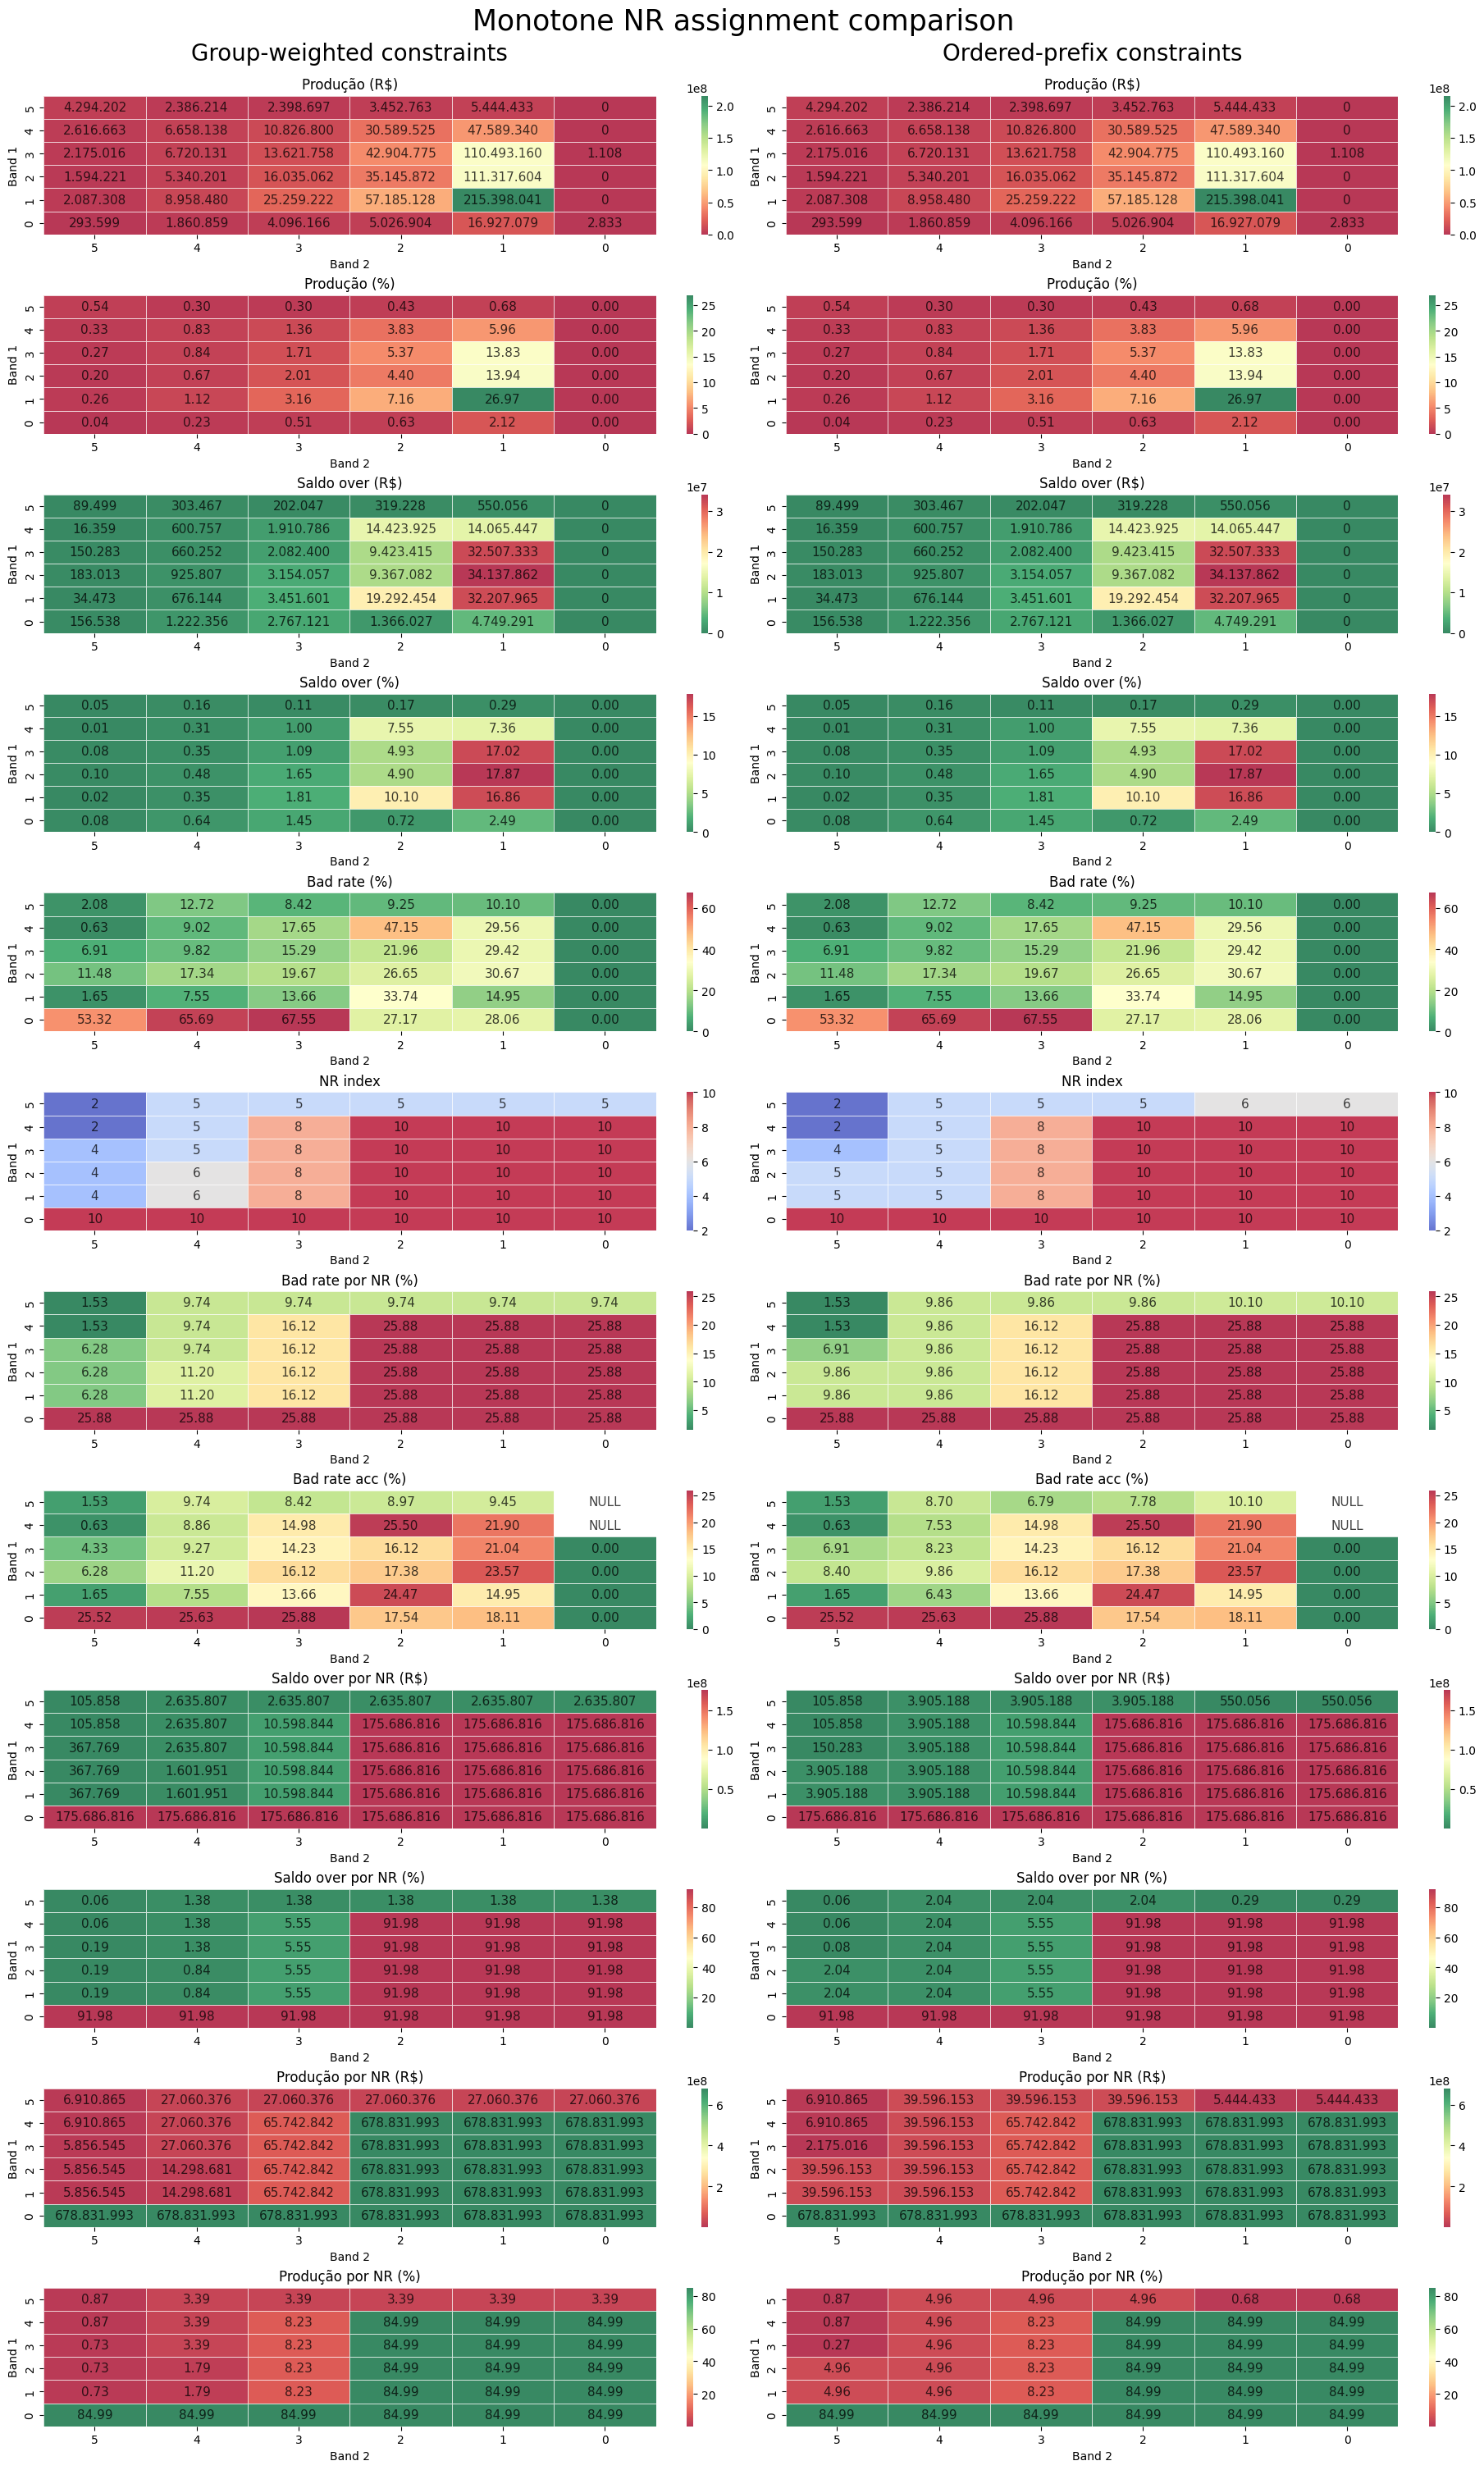

In [181]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

approaches = {
    "Group-weighted constraints": group_weighted_results,
    "Ordered-prefix constraints": ordered_prefix_results,
}

approach_pdfs = {
    name: result.toPandas()
    for name, result in approaches.items()
}

heatmap_metrics = [
    ("producao", "Produção (R$)", ",.0f", "RdYlGn"),
    ("producao_dist", "Produção (%)", ".2f", "RdYlGn"),
    ("saldo_over", "Saldo over (R$)", ",.0f", "RdYlGn_r"),    
    ("saldo_dist", "Saldo over (%)", ".2f", "RdYlGn_r"),
    ("bad_rate", "Bad rate (%)", ".2f", "RdYlGn_r"),
    ("NR_index", "NR index", ".0f", "coolwarm"),
    ("nr_bad_rate", "Bad rate por NR (%)", ".2f", "RdYlGn_r"),
    ("bad_rate_acc", "Bad rate acc (%)", ".2f", "RdYlGn_r"),
    ("nr_saldo", "Saldo over por NR (R$)", ",.0f", "RdYlGn_r"), 
    ("nr_saldo_dist", "Saldo over por NR (%)", ".2f", "RdYlGn_r"),   
    ("nr_producao", "Produção por NR (R$)", ",.0f", "RdYlGn"),            
    ("nr_producao_dist", "Produção por NR (%)", ".2f", "RdYlGn"),        
    # ("NR_cutoff", "NR cutoff", ".0f", "RdYlGn_r"),
]

def shared_limits(metric):
    values = [
        pdf[metric].dropna().to_numpy(dtype=float)
        for pdf in approach_pdfs.values()
    ]
    values = [v for v in values if len(v)]
    if not values:
        return None, None
    all_values = np.concatenate(values)
    return float(all_values.min()), float(all_values.max())

def draw_heatmap(ax, pdf, metric, title, fmt, cmap_name, vmin, vmax):
    matrix = (
        pdf.pivot(index="band_1", columns="band_2", values=metric)
           .sort_index(ascending=False)
           .sort_index(axis=1, ascending=False)
    )

    cmap = plt.get_cmap(cmap_name)
    cmap = cmap.copy()
    cmap.set_bad("white")

    sns.heatmap(
        matrix,
        mask=matrix.isna(),
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        annot=False,
        linewidths=0.6,
        linecolor="white",
        alpha=0.78,
        ax=ax,
    )

    for row_idx, (_, row) in enumerate(matrix.iterrows()):
        for col_idx, value in enumerate(row):
            label = "NULL" if pd.isna(value) else format(value, fmt).replace(",", ".")
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=11,
                color="black",
                alpha=0.75,
            )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Band 2")
    ax.set_ylabel("Band 1")

fig, axes = plt.subplots(
    nrows=len(heatmap_metrics),
    ncols=len(approach_pdfs),
    figsize=(18, 30),
    constrained_layout=True,
)

for row_idx, (metric, title, fmt, cmap_name) in enumerate(heatmap_metrics):
    vmin, vmax = shared_limits(metric)
    for col_idx, (approach_name, pdf) in enumerate(approach_pdfs.items()):
        draw_heatmap(
            axes[row_idx, col_idx],
            pdf,
            metric,
            title,
            fmt,
            cmap_name,
            vmin,
            vmax,
        )
        if row_idx == 0:
            axes[row_idx, col_idx].text(
                0.5,
                1.22,
                approach_name,
                transform=axes[row_idx, col_idx].transAxes,
                ha="center",
                va="bottom",
                fontsize=20,
                # fontweight="bold",
            )

fig.suptitle("Monotone NR assignment comparison", fontsize=25)
plt.show()